# Assignment 9 — Local Binary Pattern and Image Denoising

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.camera()   # 'cameraman' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


## Question 1

> **Question 1:** Write a program to implement the local binary pattern on a grayscale image.

Each of the 8 neighbours of a pixel is compared with the centre pixel $g_c$. A neighbour $\ge g_c$ gives bit 1, otherwise bit 0. Reading the bits clockwise from the top-left neighbour gives an 8-bit code (0–255):
$$ LBP(x_c, y_c) = \sum_{p=0}^{7} s(g_p - g_c)\, 2^{7-p}, \qquad s(x) = \begin{cases}1 & x \ge 0\\ 0 & x < 0\end{cases} $$

In [3]:
# neighbour offsets (dy, dx), clockwise starting at the top-left
OFFSETS = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]

def lbp(image):
    f = image.astype(np.int16)
    p = np.pad(f, 1, mode='edge')
    h, w = f.shape
    code = np.zeros((h, w), dtype=np.uint8)
    for bit, (dy, dx) in enumerate(OFFSETS):
        neighbour = p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
        code |= ((neighbour >= f).astype(np.uint8) << (7 - bit))
    return code

# worked example on one 3x3 block
block = np.array([[90, 120, 60], [70, 100, 130], [100, 80, 110]], dtype=np.uint8)
bits = [int(block[1 + dy, 1 + dx] >= block[1, 1]) for dy, dx in OFFSETS]
print("3x3 block:\n", block)
print("Bits (clockwise from top-left):", bits, "-> binary", ''.join(map(str, bits)),
      "-> LBP =", int(''.join(map(str, bits)), 2), "| function gives:", lbp(block)[1, 1])

3x3 block:
 [[ 90 120  60]
 [ 70 100 130]
 [100  80 110]]
Bits (clockwise from top-left): [0, 1, 0, 1, 1, 0, 1, 0] -> binary 01011010 -> LBP = 90 | function gives: 90


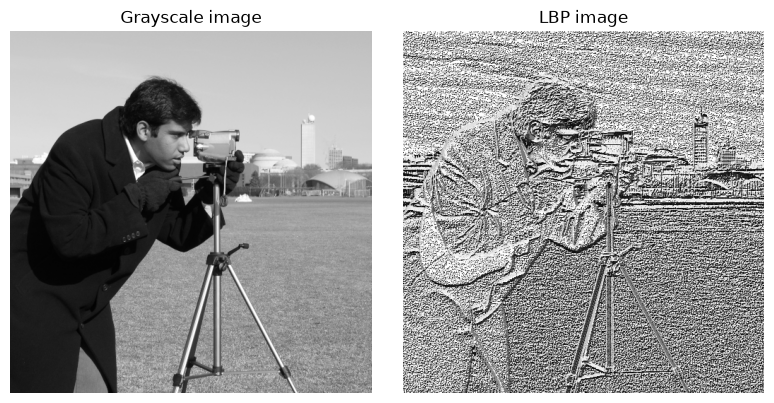

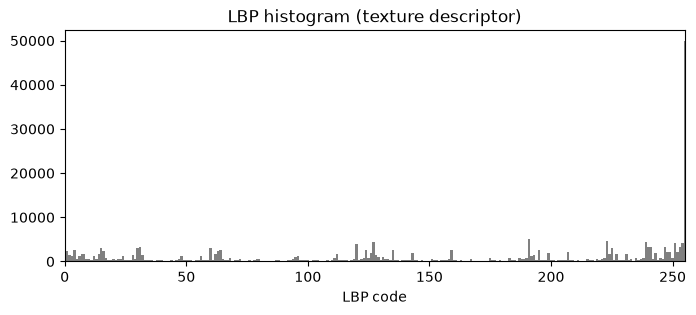

In [4]:
lbp_img = lbp(img)
show([img, lbp_img], ['Grayscale image', 'LBP image'])

plt.figure(figsize=(8, 3))
plt.bar(np.arange(256), np.bincount(lbp_img.ravel(), minlength=256), width=1, color='gray')
plt.title('LBP histogram (texture descriptor)'); plt.xlabel('LBP code'); plt.xlim(0, 255); plt.show()

**Property — invariance to brightness changes.** LBP depends only on the *sign* of differences, so adding a constant to the image does not change the codes (apart from pixels clipped at 255).

Pixels with the same LBP code after brightening by +40: 97.38 %


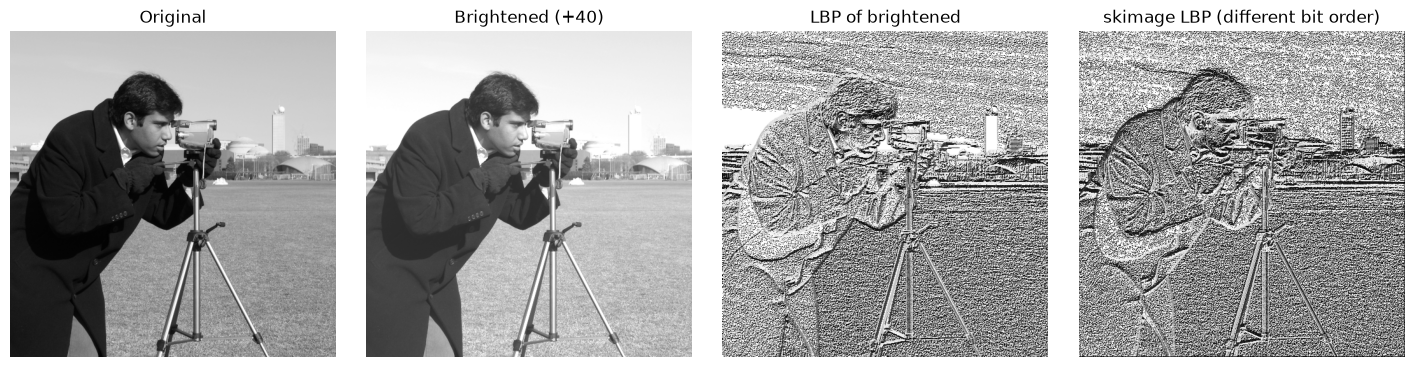

In [5]:
brighter = np.clip(img.astype(int) + 40, 0, 255).astype(np.uint8)
same = (lbp(brighter) == lbp_img).mean() * 100
print(f"Pixels with the same LBP code after brightening by +40: {same:.2f} %")

from skimage.feature import local_binary_pattern
lbp_sk = local_binary_pattern(img, P=8, R=1, method='default')
show([img, brighter, lbp(brighter), lbp_sk.astype(np.uint8)],
     ['Original', 'Brightened (+40)', 'LBP of brightened', 'skimage LBP (different bit order)'], cols=4, size=3.6)

## Question 2

> **Question 2:** Write a program to denoise the input image corrupted by Gaussian and Speckle noise by using the following filters (3x3 or 5x5 window): (a) Wiener filter (b) Median filtering (c) Gaussian filter (d) Bilateral filter.

- **Gaussian noise:** $g = f + n,\ n \sim N(0, 0.01)$ (image in [0, 1])
- **Speckle noise (multiplicative):** $g = f + f\cdot n,\ n \sim N(0, 0.04)$

Filters:
- **Wiener (adaptive, like MATLAB `wiener2`)**: $\hat f = \mu + \frac{\max(\sigma^2 - \nu^2, 0)}{\max(\sigma^2, \nu^2)}(g - \mu)$, where $\mu, \sigma^2$ are the local mean and variance and $\nu^2$ is the noise variance (estimated as the average local variance). Implemented from scratch below.
- **Median**: replaces each pixel by the median of its window.
- **Gaussian**: weighted average with Gaussian weights.
- **Bilateral**: Gaussian weights in space × Gaussian weights in intensity, so it smooths while preserving edges.

In [6]:
from scipy.ndimage import uniform_filter
from scipy.signal import wiener as scipy_wiener
from skimage.util import random_noise
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

def wiener_filter(image, k):
    g = image.astype(np.float64)
    mu = uniform_filter(g, k, mode='reflect')
    var = uniform_filter(g ** 2, k, mode='reflect') - mu ** 2
    noise = var.mean()
    out = mu + np.maximum(var - noise, 0) / np.maximum(var, noise) * (g - mu)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def median_filter(image, k):    return cv2.medianBlur(image, k)
def gaussian_filter(image, k):  return cv2.GaussianBlur(image, (k, k), 0)        # sigma derived from k
def bilateral_filter(image, k): return cv2.bilateralFilter(image, k, 50, 50)

FILTERS = {'Wiener': wiener_filter, 'Median': median_filter, 'Gaussian': gaussian_filter, 'Bilateral': bilateral_filter}

# check the Wiener implementation against scipy
ref = np.clip(np.round(scipy_wiener(img.astype(float), (5, 5))), 0, 255).astype(np.uint8)
print("Wiener: mean |mine - scipy| =", np.abs(wiener_filter(img, 5).astype(int) - ref).mean().round(3))

Wiener: mean |mine - scipy| = 0.392


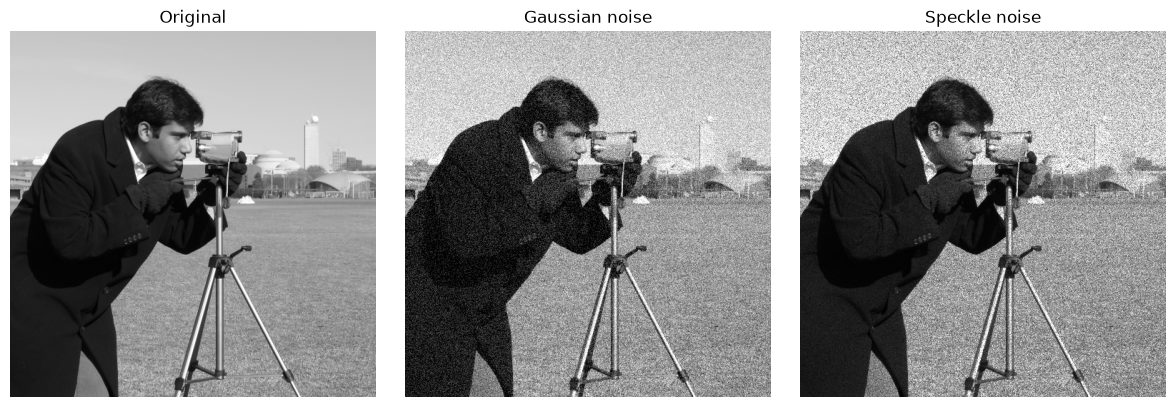

In [7]:
to8 = lambda x: (np.clip(x, 0, 1) * 255).round().astype(np.uint8)
noisy = {
    'Gaussian noise': to8(random_noise(img, mode='gaussian', var=0.01, rng=0)),
    'Speckle noise':  to8(random_noise(img, mode='speckle', var=0.04, rng=0)),
}
show([img] + list(noisy.values()), ['Original'] + list(noisy.keys()))

Enter window size to display (3 or 5): no valid input, using default = 5


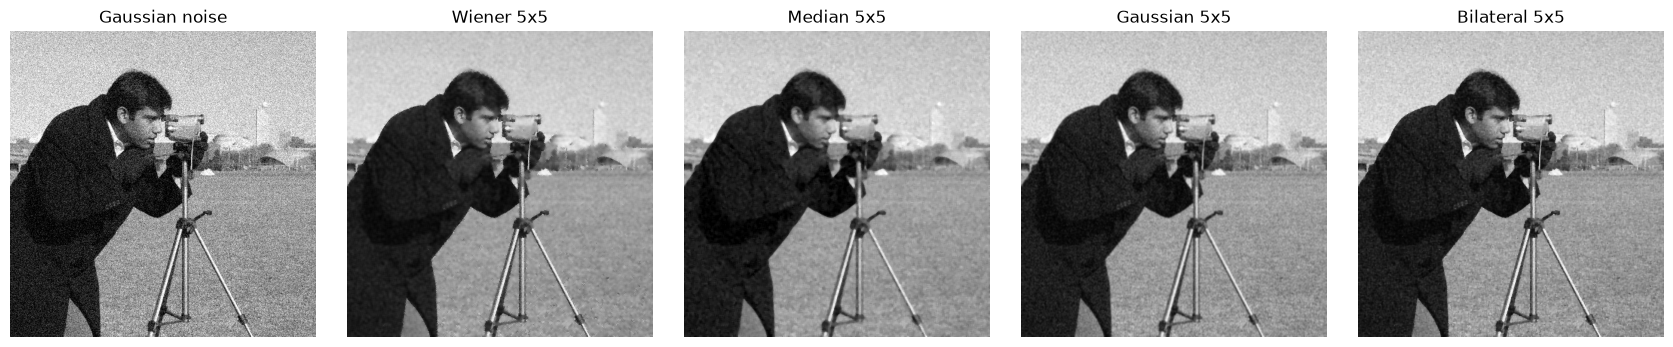

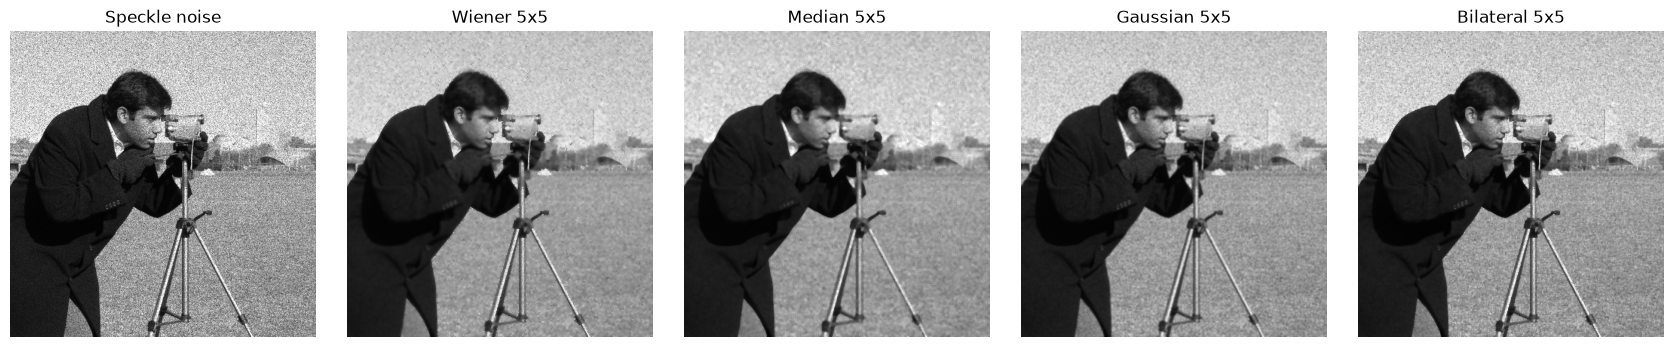

In [8]:
window = ask("Enter window size to display (3 or 5)", 5, int)
if window not in (3, 5):
    print("Window must be 3 or 5 -> using 5"); window = 5

for noise_name, g in noisy.items():
    outs = [f(g, window) for f in FILTERS.values()]
    show([g] + outs, [noise_name] + [f'{n} {window}x{window}' for n in FILTERS], cols=5, size=3.4)

## Quantitative comparison (PSNR in dB / SSIM, higher is better)

In [9]:
print(f"{'Noise':<16}{'Filter':<11}{'3x3 PSNR':>9}{'3x3 SSIM':>10}{'5x5 PSNR':>10}{'5x5 SSIM':>10}")
for noise_name, g in noisy.items():
    print(f"{noise_name:<16}{'(none)':<11}{psnr(img, g):>9.2f}{ssim(img, g):>10.3f}")
    for fname, f in FILTERS.items():
        r3, r5 = f(g, 3), f(g, 5)
        print(f"{'':<16}{fname:<11}{psnr(img, r3):>9.2f}{ssim(img, r3):>10.3f}{psnr(img, r5):>10.2f}{ssim(img, r5):>10.3f}")

Noise           Filter      3x3 PSNR  3x3 SSIM  5x5 PSNR  5x5 SSIM
Gaussian noise  (none)         20.43     0.296
                Wiener         26.63     0.571     27.73     0.695
                Median         25.73     0.494     26.28     0.606
                Gaussian       26.82     0.570     27.15     0.643
                Bilateral      25.40     0.484     27.23     0.594
Speckle noise   (none)         19.22     0.423
                Wiener         24.42     0.563     26.00     0.605
                Median         24.82     0.546     25.80     0.607
                Gaussian       26.04     0.608     26.67     0.652
                Bilateral      23.15     0.537     24.80     0.576


**Observations:**
- **LBP** turns local texture into a code per pixel. It shows fine texture and edges and does not change when a constant is added to the image brightness. The histogram of LBP codes is often used as a texture feature.
- The **Wiener** filter adapts to the local variance. It smooths flat regions strongly and keeps detail near edges, so it does very well on additive Gaussian noise.
- The **median** filter is excellent for impulse noise. For Gaussian and speckle noise it is reasonable but rounds off fine detail.
- The **Gaussian** filter reduces noise but blurs edges uniformly.
- The **bilateral** filter preserves edges best visually, but with a small window and moderate settings it removes less noise.
- 5×5 windows remove more noise than 3×3 but blur more. Speckle noise is stronger in bright regions because it is multiplicative.